<a href="https://colab.research.google.com/github/Apurba213/Ostad_AI-Ml-engineering-course/blob/main/Module13_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
#1. Dataset Loading
from tensorflow.keras.datasets import mnist

#Load Dataset
(x_train,y_train),(x_test,y_test)=mnist.load_data()

#Display dataset information
print("Training images shape:",x_train.shape)
print("Training labels shape:",y_train.shape)



Training images shape: (60000, 28, 28)
Training labels shape: (60000,)


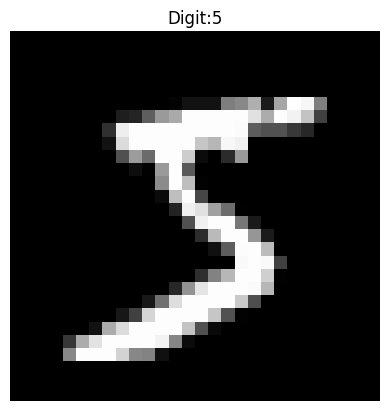

In [9]:
import matplotlib.pyplot as plt

#Display the first training image
plt.imshow(x_train[0 ],cmap="gray")

#Display its correct label
plt.title(f"Digit:{y_train[0]}")

plt.axis("off")
plt.show()

In [10]:
#2. Preprocessing
print("Before normalization:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0

print("After normalization:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

#Flattening
x_train=x_train.reshape(x_train.shape[0],784)
x_test=x_test.reshape(x_test.shape[0],784)

print("Flattened training images shape:",x_train.shape)
print("Flattened testing images shape:",x_test.shape)


Before normalization:
Minimum: 0
Maximum: 255
After normalization:
Minimum: 0.0
Maximum: 1.0
Flattened training images shape: (60000, 784)
Flattened testing images shape: (10000, 784)


In [11]:
#3.Model Architecture

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout

model = Sequential()

model.add(Dense(256, activation="relu", input_shape=(784,)))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(128, activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(64, activation="relu"))

model.add(Dense(10, activation="softmax"))

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,298 (954.29 KB)

 Trainable params: 243,530 (951.29 KB)

 Non-trainable params: 768 (3.00 KB)

In [12]:
#4.Training
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
print("Model compile Successfully")

history=model.fit(x_train,y_train,
                  batch_size=128,
                  epochs=10,
                  validation_split=0.2)


print("Training accuracy:", history.history["accuracy"])
print("Validation accuracy:", history.history["val_accuracy"])

print("Training loss:", history.history["loss"])
print("Validation loss:", history.history["val_loss"])


Model compile Successfully
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8809 - loss: 0.3870 - val_accuracy: 0.9555 - val_loss: 0.1474
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9449 - loss: 0.1783 - val_accuracy: 0.9660 - val_loss: 0.1086
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9578 - loss: 0.1364 - val_accuracy: 0.9712 - val_loss: 0.0934
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9635 - loss: 0.1147 - val_accuracy: 0.9718 - val_loss: 0.0931
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9679 - loss: 0.1014 - val_accuracy: 0.9735 - val_loss: 0.0885
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9719 - loss: 0.0876 - val_accuracy: 0.9762 - val_loss: 0.0841
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9728 - loss: 0.0855 - val_accuracy: 0.9769 - val_loss: 0.0780
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9756 - lo

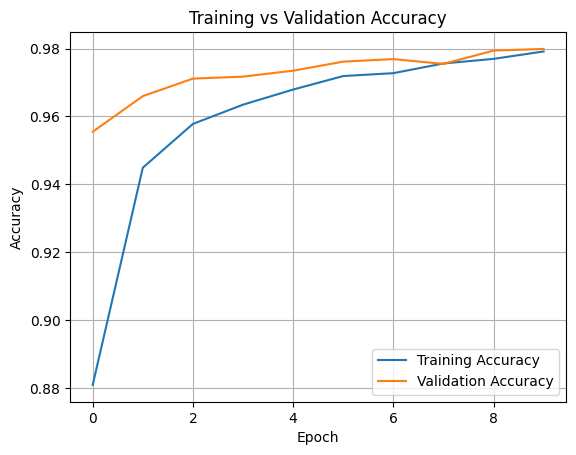

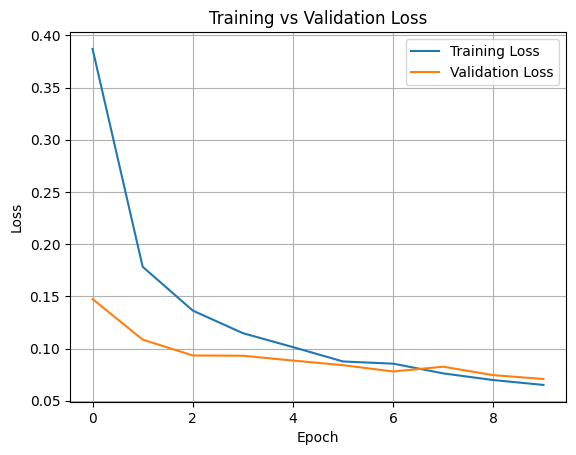

In [13]:
#5.Visualization

import matplotlib.pyplot as plt

# Get accuracy values from training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

# Plot both lines
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()



# Get loss values from training history
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Plot both lines
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9793 - loss: 0.0719
Test Loss: 0.07193784415721893
Test Accuracy: 0.9793000221252441
Test Accuracy (%): 97.93000221252441


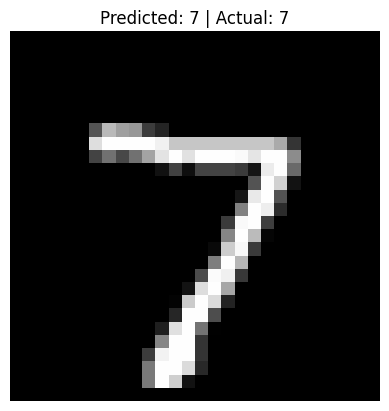

Predicted digit: 7
Actual digit: 7
Confidence: 99.98762 %


In [14]:
#6.Evaluation

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)


import numpy as np
import matplotlib.pyplot as plt

# Select one test image
index = 0
image = x_test[index]

# Predict the digit
probabilities = model.predict(image.reshape(1, 784), verbose=0)

# Get the predicted class
predicted_digit = np.argmax(probabilities[0])

# Get the actual label
actual_digit = y_test[index]

# Display the image and results
plt.imshow(image.reshape(28, 28), cmap="gray")
plt.title(
    f"Predicted: {predicted_digit} | Actual: {actual_digit}"
)
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Actual digit:", actual_digit)
print("Confidence:", probabilities[0][predicted_digit] * 100, "%")


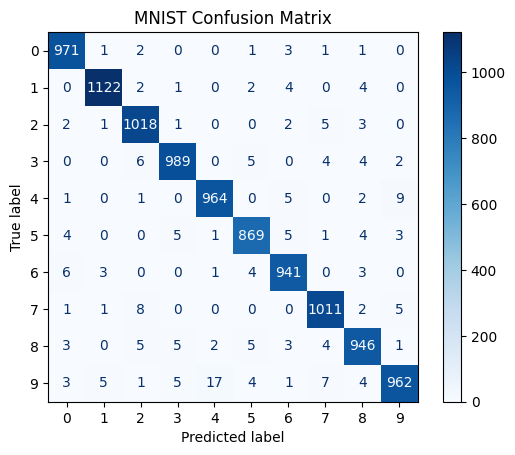

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict the test images
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display it
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Blues", values_format="d")
plt.title("MNIST Confusion Matrix")
plt.show()